<a href="https://colab.research.google.com/github/onumaechimargaret-wq/My-Project-work-gas-adsorption-modelling-python/blob/SEPARATION-COURSEWORK/SEPARATION_COURSEWORK_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
"""Experimental data (Table 1) and column/operating parameters (Table 2).

Mission O2 - selecting an adsorbent for an oxygen concentrator on Europa.
"""
import numpy as np

# ---------------------------------------------------------------------------
# Table 1: single-component isotherms at 303 K.  P in Pa, q in mol/kg
# -----------------------------------------------------

ISOTHERMS = {
    "Romulus": {
        "N2": (
            np.array([0.000, 2026.500, 3039.750, 4053.000, 6079.500, 8106.000,
                      61909.575, 111356.175, 173265.750, 247435.650,
                      321706.875, 395978.100, 470148.000, 544419.225,
                      618690.450]),
            np.array([0.000, 0.025, 0.038, 0.053, 0.079, 0.108, 0.562, 0.835,
                      1.082, 1.295, 1.482, 1.597, 1.714, 1.795, 1.861]),
        ),
        "O2": (
            np.array([0.000, 8106.000, 20265.000, 247435.650, 371153.475,
                      494871.300, 618690.450]),
            np.array([0.000, 0.015, 0.035, 0.366, 0.521, 0.693, 0.815]),
        ),
    },
    "Remus": {
        "N2": (
            np.array([0, 63400, 88700, 117500, 162500, 208500, 303800,
                      427000, 609500, 776600, 919000], dtype=float),
            np.array([0.000, 0.1674, 0.2300, 0.2994, 0.3934, 0.4848, 0.6450,
                      0.8280, 1.0588, 1.2249, 1.3472]),
        ),
        "O2": (
            np.array([0, 33200, 61300, 96100, 143200, 214800, 355900,
                      548200, 747900, 859000, 931700], dtype=float),
            np.array([0.000, 0.0372, 0.0679, 0.1022, 0.1504, 0.2138, 0.3455,
                      0.5089, 0.6830, 0.7679, 0.8348]),
        ),
    },
}

# ---------------------------------------------------------------------------
# Table 2: column, properties and operating conditions
# ---------------------------------------------------------------------------

PARAMS = {
    "L": 0.32,            # column length [m]
    "eps": 0.32,          # bed void fraction [-]
    "rho_s": 990.0,       # particle density [kg/m3]
    "r_p": 1.0e-3,        # particle radius [m]
    "tau": 3.0,           # tortuosity [-]
    "D_m": 7.481e-5,      # molecular diffusivity [m2/s]
    "R": 8.314,           # gas constant [m3 Pa / (mol K)]
    "T": 303.0,           # temperature [K]
    "P": 100.0e3,         # pressure [Pa]
    "v_in": 4.864e-3,     # inlet interstitial velocity [m/s]
    # --- assumption (not given in the brief) ---
    "eps_p": 0.35,        # particle (macropore) voidage [-], Haghpanah et al. 2013
}


ISOTHERM FITTING RESULTS (T = 303 K)

Romulus - N2  (15 points)
  Model                      R2      RMSE      AICc   Parameters (b in 1/Pa) +/- 95% CI
  Langmuir              0.99972    0.0122   -127.31   qs=2.542±0.052, b=4.35e-06±2.2e-07
  Sips                  0.99994    0.0055   -147.73   qs=2.771±0.083, b=3.564e-06±2.6e-07, n=0.914±0.024
  Dual-site Langmuir    0.99996    0.0048   -148.09   qs1=2.44±0.16, b1=3.258e-06±5.6e-07, qs2=0.2508±0.22, b2=2.463e-05±1.9e-05

Romulus - O2  (7 points)
  Model                      R2      RMSE      AICc   Parameters (b in 1/Pa) +/- 95% CI
  Langmuir              0.99960    0.0063    -63.98   qs=4.705±1.5, b=3.414e-07±1.3e-07
  Sips                  0.99960    0.0063    -56.98   qs=4.7±6.3, b=3.419e-07±6.5e-07, n=1±0.19
  Dual-site Langmuir    0.99961    0.0062    -43.18   qs1=0.00215±0.038, b1=0.01±18, qs2=4.843±2.9, b2=3.287e-07±2.5e-07

Remus - N2  (11 points)
  Model                      R2      RMSE      AICc   Parameters (b in 1/Pa) +/- 

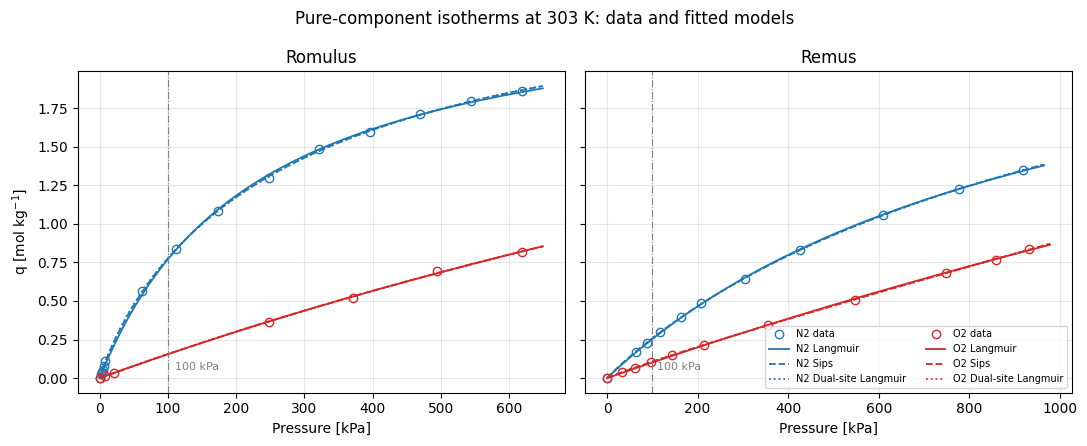

In [32]:
"""
Mission O2 - Static measurements

1. Loads the pure-component isotherm data (Table 1) for N2 and O2 on Romulus and Remus at 303 K.
2. Fits three candidate isotherm models by non-linear least squares:
     - Single-site Langmuir (SSL)      q = qs*b*P / (1 + b*P)
     - Sips (Langmuir-Freundlich)      q = qs*(b*P)^n / (1 + (b*P)^n)
     - Dual-site Langmuir (DSL)        q = qs1*b1*P/(1+b1*P) + qs2*b2*P/(1+b2*P)
3. Compares the models with R^2, RMSE and AIC (AIC penalises extra parameters).
4. Compares the adsorbents: capacity at 100 kPa, Henry constants, and N2/O2 selectivity.
5. Plots data vs fits and saves the chosen parameters to isotherm_params.json
   so the breakthrough (dynamic) model can load them directly.

Units: P in Pa, q in mol/kg, b in 1/Pa.
"""

import json
import numpy as np
from scipy.optimize import least_squares
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------------
# 1. Experimental data (Table 1, 303 K)
# ----------------------------------------------------------------------------
# Removed the invalid external import 'from data import ISOTHERMS' because
# ISOTHERMS is already defined in the previous notebook cell (6axsJgOQfXNl).

DATA = {
    ads: {
        gas: {"P": pressure, "q": loading}
        for gas, (pressure, loading) in gases.items()
    }
    for ads, gases in ISOTHERMS.items()
}

T = 303.0          # K
P_FEED = 100e3     # Pa, process pressure (Table 2)


# ----------------------------------------------------------------------------
# 2. Isotherm models
#    Parameters are fitted in a scaled form (b in 1/kPa) so the optimiser sees
#    numbers of similar magnitude; they are converted back to 1/Pa afterwards.
# ----------------------------------------------------------------------------
def langmuir(P, qs, b):
    return qs * b * P / (1.0 + b * P)


def sips(P, qs, b, n):
    x = (b * P) ** n
    return qs * x / (1.0 + x)


def dual_langmuir(P, qs1, b1, qs2, b2):
    return langmuir(P, qs1, b1) + langmuir(P, qs2, b2)


MODELS = {
    "Langmuir": {
        "f": langmuir,
        "names": ["qs", "b"],
        "p0": [2.0, 1e-3],                 # b in 1/kPa during fitting
        "lb": [1e-6, 1e-8],
        "ub": [100.0, 10.0],
        "b_index": [1],                    # which parameters are affinities
    },
    "Sips": {
        "f": sips,
        "names": ["qs", "b", "n"],
        "p0": [2.0, 1e-3, 1.0],
        "lb": [1e-6, 1e-8, 0.2],
        "ub": [100.0, 10.0, 3.0],
        "b_index": [1],
    },
    "Dual-site Langmuir": {
        "f": dual_langmuir,
        "names": ["qs1", "b1", "qs2", "b2"],
        "p0": [1.0, 1e-2, 1.0, 1e-3],
        "lb": [1e-6, 1e-8, 1e-6, 1e-8],
        "ub": [100.0, 10.0, 100.0, 10.0],
        "b_index": [1, 3],
    },
}


def fit_model(model_name, P_pa, q):
    """Fit one model to one data set. Returns parameters (b in 1/Pa) and statistics."""
    m = MODELS[model_name]
    P_kpa = P_pa / 1e3

    def residuals(p):
        return m["f"](P_kpa, *p) - q

    # Try a few starting points and keep the best: non-linear fits can get stuck
    best = None
    rng = np.random.default_rng(0)
    starts = [np.array(m["p0"])]
    for _ in range(20):
        starts.append(np.array(m["p0"]) * 10 ** rng.uniform(-1, 1, len(m["p0"])))

    for x0 in starts:
        x0 = np.clip(x0, np.array(m["lb"]) * 1.0001, np.array(m["ub"]) * 0.9999)
        res = least_squares(residuals, x0, bounds=(m["lb"], m["ub"]),
                            method="trf", x_scale="jac", max_nfev=20000)
        if best is None or res.cost < best.cost:
            best = res

    p = best.x.copy()
    resid = best.fun
    n_pts = len(q)
    k = len(p)
    sse = float(np.sum(resid ** 2))
    sst = float(np.sum((q - q.mean()) ** 2))
    r2 = 1.0 - sse / sst
    rmse = np.sqrt(sse / n_pts)
    # Corrected AIC for small samples (lower = better)
    aic = n_pts * np.log(sse / n_pts) + 2 * k
    aicc = aic + (2 * k * (k + 1)) / (n_pts - k - 1) if n_pts - k - 1 > 0 else np.inf

    # Approximate 95 % confidence intervals from the Jacobian
    try:
        J = best.jac
        cov = np.linalg.inv(J.T @ J) * sse / max(n_pts - k, 1)
        ci95 = 1.96 * np.sqrt(np.diag(cov))
    except np.linalg.LinAlgError:
        ci95 = np.full(k, np.nan)

    # Convert affinity constants back from 1/kPa to 1/Pa
    for i in m["b_index"]:
        p[i] /= 1e3
        ci95[i] /= 1e3

    return {
        "params": dict(zip(m["names"], p.tolist())),
        "ci95": dict(zip(m["names"], ci95.tolist())),
        "R2": r2, "RMSE": rmse, "AICc": aicc, "SSE": sse,
    }


def evaluate(model_name, params, P_pa):
    """Evaluate a fitted model at pressure(s) in Pa."""
    m = MODELS[model_name]
    return m["f"](np.asarray(P_pa, dtype=float), *[params[n] for n in m["names"]])


def henry_constant(model_name, params):
    """Initial slope dq/dP at P -> 0, in mol/(kg Pa)."""
    if model_name == "Langmuir":
        return params["qs"] * params["b"]
    if model_name == "Dual-site Langmuir":
        return params["qs1"] * params["b1"] + params["qs2"] * params["b2"]
    if model_name == "Sips":
        # Finite only for n = 1; for n != 1 report a numerical slope at low P
        P_low = 100.0
        return float(evaluate(model_name, params, P_low)) / P_low
    raise ValueError(model_name)


# ----------------------------------------------------------------------------
# 3. Fit everything
# ----------------------------------------------------------------------------
results = {}
for ads, gases in DATA.items():
    results[ads] = {}
    for gas, d in gases.items():
        P = np.array(d["P"], dtype=float)
        q = np.array(d["q"], dtype=float)
        results[ads][gas] = {name: fit_model(name, P, q) for name in MODELS}

print("=" * 88)
print("ISOTHERM FITTING RESULTS (T = 303 K)")
print("=" * 88)
for ads in results:
    for gas in results[ads]:
        print(f"\n{ads} - {gas}  ({len(DATA[ads][gas]['q'])} points)")
        print(f"  {'Model':<20}{'R2':>9}{'RMSE':>10}{'AICc':>10}   Parameters (b in 1/Pa) +/- 95% CI")
        for name, r in results[ads][gas].items():
            pstr = ", ".join(f"{k}={v:.4g}±{r['ci95'][k]:.2g}" for k, v in r["params"].items())
            print(f"  {name:<20}{r['R2']:>9.5f}{r['RMSE']:>10.4f}{r['AICc']:>10.2f}   {pstr}")

# ----------------------------------------------------------------------------
# 4. Model selection
#    The breakthrough model needs a multicomponent isotherm. The single-site
#    Langmuir extends naturally to the extended (competitive) Langmuir model,
#    which is thermodynamically consistent when qs is shared. We therefore
#    choose the simplest model that fits adequately, and report AICc so the
#    choice is justified rather than assumed.
# ----------------------------------------------------------------------------
CHOSEN = "Langmuir"

print("\n" + "=" * 88)
print(f"ADSORBENT COMPARISON using the {CHOSEN} fits")
print("=" * 88)
summary = {}
for ads in results:
    pN2 = results[ads]["N2"][CHOSEN]["params"]
    pO2 = results[ads]["O2"][CHOSEN]["params"]
    KN2 = henry_constant(CHOSEN, pN2)
    KO2 = henry_constant(CHOSEN, pO2)
    qN2_feed = float(evaluate(CHOSEN, pN2, P_FEED))
    qO2_feed = float(evaluate(CHOSEN, pO2, P_FEED))

    # (a) Henry's-law (low-pressure) selectivity
    S_henry = KN2 / KO2
    # (b) Ratio of pure-component capacities at 100 kPa
    S_pure = qN2_feed / qO2_feed
    # (c) Extended-Langmuir selectivity for an equimolar mixture at 100 kPa
    #     S = (qN2/qO2)/(yN2/yO2) = (qsN2*bN2)/(qsO2*bO2) for extended Langmuir
    #     -> identical to Henry selectivity, independent of composition.
    summary[ads] = {
        "K_N2 [mol/kg/Pa]": KN2, "K_O2 [mol/kg/Pa]": KO2,
        "q_N2 at 100 kPa [mol/kg]": qN2_feed, "q_O2 at 100 kPa [mol/kg]": qO2_feed,
        "Henry selectivity N2/O2": S_henry,
        "Pure-component capacity ratio at 100 kPa": S_pure,
    }
    print(f"\n{ads}")
    for k, v in summary[ads].items():
        print(f"  {k:<45}{v:.4g}")

# ----------------------------------------------------------------------------
# 5. Figure: data and fits
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
colours = {"N2": "tab:blue", "O2": "tab:red"}
styles = {"Langmuir": "-", "Sips": "--", "Dual-site Langmuir": ":"}

for ax, ads in zip(axes, DATA):
    for gas, d in DATA[ads].items():
        P = np.array(d["P"]) / 1e3
        ax.plot(P, d["q"], "o", color=colours[gas], mfc="none", label=f"{gas} data")
        P_fine = np.linspace(0, max(d["P"]) * 1.05, 300)
        for name, ls in styles.items():
            q_fit = evaluate(name, results[ads][gas][name][params], P_fine) if 'params' in locals() else evaluate(name, results[ads][gas][name]["params"], P_fine)
            ax.plot(P_fine / 1e3, q_fit, ls, color=colours[gas], lw=1.3,
                    label=f"{gas} {name}")
    ax.axvline(P_FEED / 1e3, color="grey", lw=0.8, ls="-.")
    ax.text(P_FEED / 1e3 + 10, 0.05, "100 kPa", color="grey", fontsize=8)
    ax.set_title(ads)
    ax.set_xlabel("Pressure [kPa]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("q [mol kg$^{-1}$]")
axes[1].legend(fontsize=7, ncol=2, loc="lower right")
fig.suptitle("Pure-component isotherms at 303 K: data and fitted models")
fig.tight_layout()
fig.savefig("isotherm_fits.png", dpi=200)
print("\nFigure saved to isotherm_fits.png")

# ----------------------------------------------------------------------------
# 6. Save parameters for the dynamic (breakthrough) model
# ----------------------------------------------------------------------------
out = {
    "temperature_K": T,
    "chosen_model": CHOSEN,
    "units": {"qs": "mol/kg", "b": "1/Pa"},
    "fits": results,
    "comparison": summary,
}
with open("isotherm_params.json", "w") as fh:
    json.dump(out, fh, indent=2)
print("Parameters saved to isotherm_params.json")